In [4]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv
import time

In [2]:
load_dotenv()

True

In [3]:
class CrashState(TypedDict):
    input: str
    step1: str
    step2: str
    step3: str

In [5]:
def step_1(state: CrashState) -> CrashState:
    print("Step 1 executed")
    return {'step1': 'done', 'input': state['input']}

def step_2(state: CrashState) -> CrashState:
    print('Step 2 hanging... now manually interrupt from notebook')
    # simulate long-running hang
    time.sleep(30) 
    return {'step2': 'done'}

def step_3(state: CrashState) -> CrashState:
    print('Step 3 executed')
    return {'step3': 'done'}

In [7]:
graph = StateGraph(CrashState)

graph.add_node('step 1', step_1)
graph.add_node('step 2', step_2)
graph.add_node('step 3', step_3)

graph.add_edge(START, 'step 1')
graph.add_edge('step 1', 'step 2')
graph.add_edge('step 2', 'step 3')
graph.add_edge('step 3', END)

checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

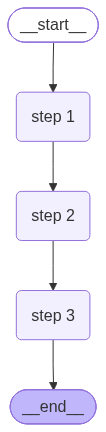

In [8]:
workflow

In [10]:
try:
    print('running graph: manually interrupt during step 2')
    workflow.invoke({'input': 'start'}, config={'configurable':{'thread_id': 'thread-1'}})
except KeyboardInterrupt:
    print('Kernal manually interrupted (crash simulated)')

running graph: manually interrupt during step 2
Step 1 executed
Step 2 hanging... now manually interrupt from notebook
Kernal manually interrupted (crash simulated)


In [12]:
workflow.get_state({'configurable':{'thread_id': 'thread-1'}})

StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step 2',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6ef1-ce2b-62d9-8001-2a1972d46e68'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-02T18:56:29.534273+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6ef1-ce29-692d-8000-19d16babd0f3'}}, tasks=(PregelTask(id='cfe71906-4820-da56-4ee0-75ab4badf8da', name='step 2', path=('__pregel_pull', 'step 2'), error=None, interrupts=(), state=None, result=None),), interrupts=())

In [14]:
list(workflow.get_state_history({'configurable':{'thread_id': 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step 2',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6ef1-ce2b-62d9-8001-2a1972d46e68'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-02T18:56:29.534273+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6ef1-ce29-692d-8000-19d16babd0f3'}}, tasks=(PregelTask(id='cfe71906-4820-da56-4ee0-75ab4badf8da', name='step 2', path=('__pregel_pull', 'step 2'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'input': 'start'}, next=('step 1',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6ef1-ce29-692d-8000-19d16babd0f3'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-02T18:56:29.533610+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'ch

In [15]:
# Re-run to show fault - tolerant resume
final_state = workflow.invoke(None, config= {'configurable':{'thread_id': 'thread-1'}})
print(final_state)

Step 2 hanging... now manually interrupt from notebook
Step 3 executed
{'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}


In [16]:
workflow.get_state({'configurable':{'thread_id': 'thread-1'}})

StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6eff-68f6-6e46-8003-9f93a0ed6032'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-11-02T19:02:34.731860+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6eff-68f2-6669-8002-2885acd56089'}}, tasks=(), interrupts=())

In [17]:
list(workflow.get_state_history({'configurable':{'thread_id': 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6eff-68f6-6e46-8003-9f93a0ed6032'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-11-02T19:02:34.731860+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6eff-68f2-6669-8002-2885acd56089'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done'}, next=('step 3',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6eff-68f2-6669-8002-2885acd56089'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-02T19:02:34.730005+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6ef1-ce2b-62d9-8001-2a1972d46e68'}}, tasks=(PregelTask(id='fe7ed4c8-5f3f-3aa2